# =============================================================
# Titanic Dataset: Data Preprocessing and Exploratory Data Analysis (EDA)
# =============================================================

In [32]:
#  Importing Libraries and Loading the Dataset

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, MinMaxScaler, StandardScaler

In [33]:
# Load Titanic dataset

df = sns.load_dataset('titanic')

In [34]:
# Handling Missing Values

In [35]:
print("Missing values before cleaning:")
print(df.isnull().sum())

df['age'] = df['age'].fillna(df['age'].median())
df['fare'] = df['fare'].fillna(df['fare'].median())
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])
df['embark_town'] = df['embark_town'].fillna(df['embark_town'].mode()[0])

# deck: too sparse to impute, so drop it
df = df.drop(columns=['deck'])

print("\nMissing values after cleaning:")
print(df.isnull().sum())

Missing values before cleaning:
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

Missing values after cleaning:
survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64


<Figure size 1600x900 with 0 Axes>

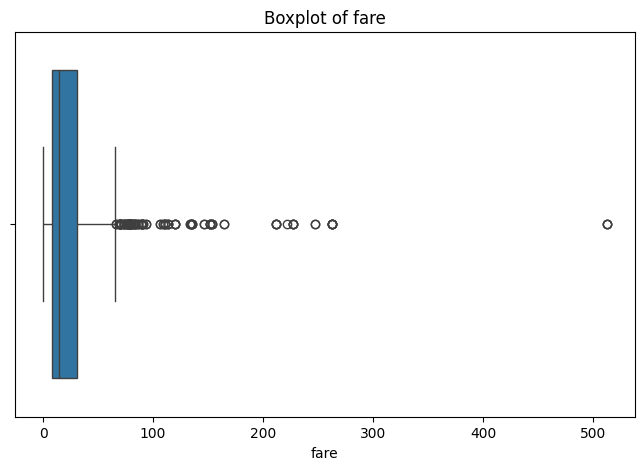

In [36]:
# Handling Outliers

plt.figure(figsize=(16,9))
fig, ax = plt.subplots(figsize=(8,5))
sns.boxplot(x=df['fare'])
plt.title("Boxplot of fare")
plt.show()



In [37]:
before = df.shape[0]
Q1 = df['fare'].quantile(0.25)
Q3 = df['fare'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
df = df[(df['fare'] >= lower_bound) & (df['fare'] <= upper_bound)]
after = df.shape[0]
print("Rows before", before)
print("Rows after", after)

Rows before 891
Rows after 775


In [38]:
le = LabelEncoder()
df['sex_encoded'] = le.fit_transform(df['sex'])

if 'embark_town' in df.columns:
    df = pd.get_dummies(df, columns=['embark_town'], drop_first=True, dtype=int)

print(df.head())

   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   
5         0       3    male  28.0      0      0   8.4583        Q  Third   

     who  adult_male alive  alone  sex_encoded  embark_town_Queenstown  \
0    man        True    no  False            1                       0   
2  woman       False   yes   True            0                       0   
3  woman       False   yes  False            0                       0   
4    man        True    no   True            1                       0   
5    man        True    no   True            1                       1   

   embark_town_Southampton  
0                        1  
2                        1  
3          

In [39]:
# Feature Scaling

scaler = StandardScaler()
df[['age_scaled', 'fare_scaled']] = scaler.fit_transform(df[['age', 'fare']])

minmax_scaler = MinMaxScaler()
df[['age_minmax', 'fare_minmax']] = minmax_scaler.fit_transform(df[['age', 'fare']])
print(df[['age_scaled', 'fare_scaled', 'age_minmax', 'fare_minmax']].head())

   age_scaled  fare_scaled  age_minmax  fare_minmax
0   -0.528321    -0.779117    0.271174     0.111538
2   -0.215182    -0.729373    0.321438     0.121923
3    0.489381     2.599828    0.434531     0.816923
4    0.489381    -0.720161    0.434531     0.123846
5   -0.058613    -0.690071    0.346569     0.130128


In [40]:
# Feature Engineering

df['family_size'] = df['sibsp'] + df['parch'] + 1
df['is_alone'] = (df['family_size']==1).astype(int)

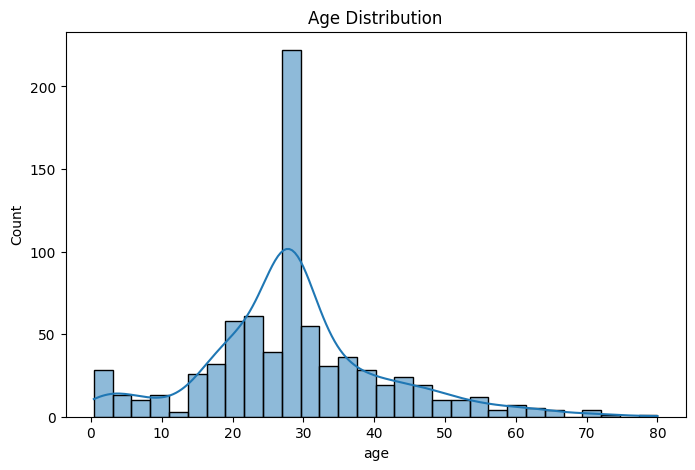

In [41]:
# Univariate Analysis
plt.figure(figsize=(8,5))
sns.histplot(df['age'], kde=True, bins=30)
plt.title("Age Distribution")
plt.show()

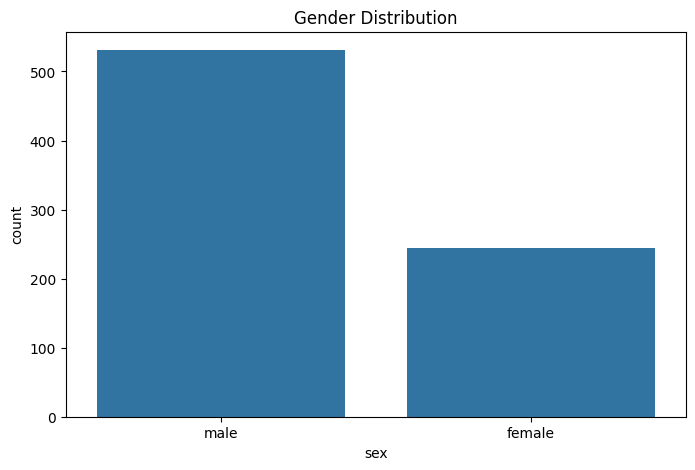

In [42]:
plt.figure(figsize=(8,5))
sns.countplot(x=df['sex'])
plt.title('Gender Distribution')
plt.show()

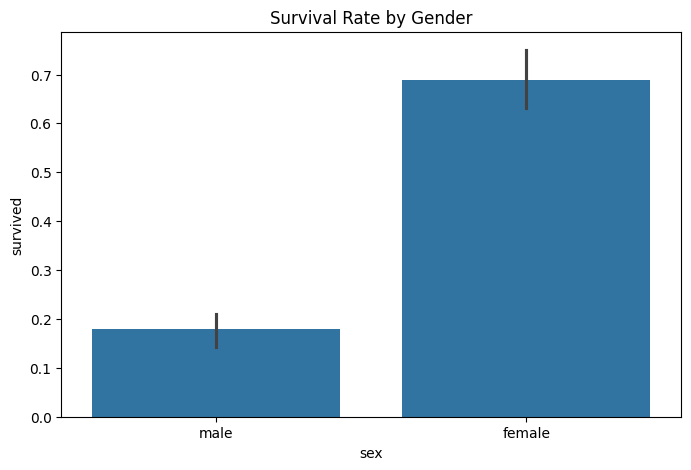

In [43]:
# Bivariate Analysis
plt.figure(figsize=(8,5))
sns.barplot(x='sex', y='survived', data=df)
plt.title('Survival Rate by Gender')
plt.show()

Text(0.5, 1.0, 'Survival Rate by Passenger Class')

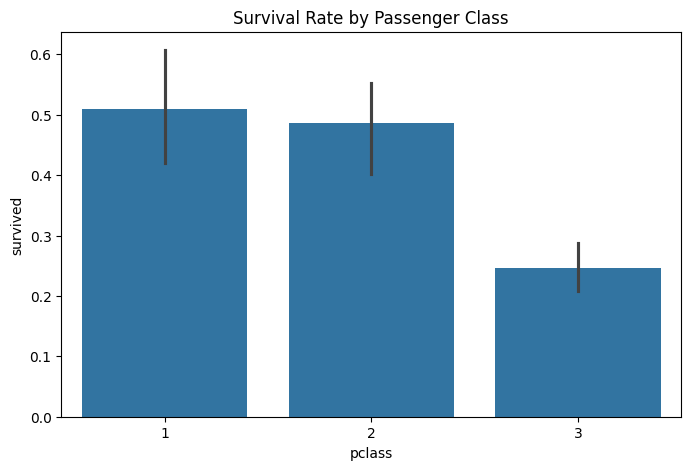

In [44]:
plt.figure(figsize=(8,5))
sns.barplot(x='pclass', y='survived',  data=df)
plt.title("Survival Rate by Passenger Class")

Text(0.5, 1.0, 'Age Distribution by Survival')

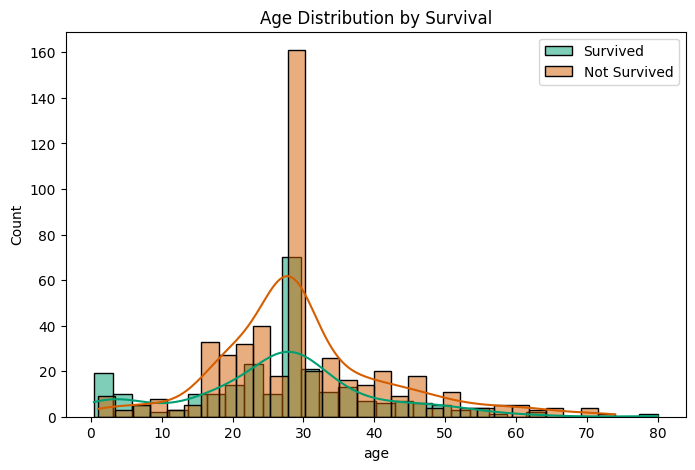

In [52]:
plt.figure(figsize=(8,5))
sns.histplot(df[df['survived'] == 1]['age'], kde=True, bins=30, label="Survived", color="#009E73", alpha=0.5)
sns.histplot(df[df['survived'] == 0]['age'], kde=True, bins=30, label="Not Survived", color="#D55E00", alpha=0.5)
plt.legend()
plt.title("Age Distribution by Survival")

In [46]:
df.head(15)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,...,alone,sex_encoded,embark_town_Queenstown,embark_town_Southampton,age_scaled,fare_scaled,age_minmax,fare_minmax,family_size,is_alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,...,False,1,0,1,-0.528321,-0.779117,0.271174,0.111538,2,0
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,...,True,0,0,1,-0.215182,-0.729373,0.321438,0.121923,1,1
3,1,1,female,35.0,1,0,53.1000,S,First,woman,...,False,0,0,1,0.489381,2.599828,0.434531,0.816923,2,0
4,0,3,male,35.0,0,0,8.0500,S,Third,man,...,True,1,0,1,0.489381,-0.720161,0.434531,0.123846,1,1
5,0,3,male,28.0,0,0,8.4583,Q,Third,man,...,True,1,1,0,-0.058613,-0.690071,0.346569,0.130128,1,1
6,0,1,male,54.0,0,0,51.8625,S,First,man,...,True,1,0,1,1.976792,2.508630,0.673285,0.797885,1,1
7,0,3,male,2.0,3,1,21.0750,S,Third,child,...,False,1,0,1,-2.094017,0.239725,0.019854,0.324231,5,0
8,1,3,female,27.0,0,2,11.1333,S,Third,woman,...,False,0,0,1,-0.136897,-0.492935,0.334004,0.171282,3,0
9,1,2,female,14.0,1,0,30.0708,C,Second,child,...,False,0,0,0,-1.154600,0.902677,0.170646,0.462628,2,0
10,1,3,female,4.0,1,1,16.7000,S,Third,child,...,False,0,0,1,-1.937447,-0.082693,0.044986,0.256923,3,0
